<a href="https://colab.research.google.com/github/SchusterFelipe/intel-image-classification-cnn/blob/main/TrabalhoGB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Trabalho do Grau B - Classificação de Imagens com CNNs e Transfer Learning

Autor: Felipe Fröhlich Schuster

Link da apresentação: https://asavbrm-my.sharepoint.com/:v:/g/personal/schusterfelipe_edu_unisinos_br/IQAg_uRwTKHXTq-9JksT-9KfAaSAEwJTIvmUk-6yOM5qkZk?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=BnBqfm

Link do Colab Executado (já que seria necessário ter os arquivos baixados no Google Drive para conseguir usar o dataset): https://asavbrm-my.sharepoint.com/:v:/g/personal/schusterfelipe_edu_unisinos_br/IQB1c7ciLNvoQJZd2Zq_HaqKAUPanSpRL2elOqzaOYCatrA?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=yXdSDd

### Resumo
Este trabalho teve como objetivo aplicar técnicas de aprendizado profundo para o problema de classificação de imagens utilizando redes neurais convolucionais (CNNs). O dataset utilizado foi o Intel Image Classification, disponível na plataforma Kaggle, contendo imagens de diferentes cenários naturais e urbanos distribuídas em seis classes.

Foram implementadas duas abordagens distintas: uma CNN treinada do zero e um modelo baseado em Transfer Learning utilizando a arquitetura MobileNetV2 pré-treinada no ImageNet. O objetivo foi comparar o desempenho das abordagens em termos de acurácia, capacidade de generalização e custo computacional.

Os resultados obtidos demonstraram que a abordagem baseada em Transfer Learning apresentou desempenho superior à CNN construída manualmente, alcançando maior acurácia e convergência mais rápida durante o treinamento. Esses resultados evidenciam a eficácia da reutilização de modelos pré-treinados em problemas de classificação de imagens.

### Introdução
A classificação de imagens é uma das principais aplicações de aprendizado profundo e visão computacional, sendo utilizada em áreas como reconhecimento facial, veículos autônomos, diagnóstico médico e monitoramento ambiental.

Redes neurais convolucionais (CNNs) são amplamente utilizadas nesse contexto devido à sua capacidade de extrair automaticamente características relevantes das imagens. Diferentemente de abordagens tradicionais, CNNs aprendem padrões diretamente dos dados, reduzindo a necessidade de engenharia manual de atributos e permitindo a identificação de estruturas visuais complexas.

Técnicas de Transfer Learning passaram a ser amplamente utilizadas por possibilitarem o reaproveitamento de modelos previamente treinados em grandes conjuntos de dados, reduzindo tempo de treinamento e melhorando o desempenho em novos problemas.

Neste trabalho será utilizado o dataset Intel Image Classification para avaliar o desempenho de diferentes arquiteturas de CNN em um problema de classificação multiclasse. Serão comparadas uma CNN construída manualmente e uma abordagem baseada em Transfer Learning utilizando a arquitetura MobileNetV2. A análise será realizada por meio de métricas de desempenho, curvas de aprendizado e avaliação da capacidade de generalização dos modelos.

### Descrição do Dataset
O dataset utilizado é o Intel Image Classification, disponível na plataforma Kaggle:
https://www.kaggle.com/datasets/puneet6060/intel-image-classification

O conjunto de dados contém aproximadamente 17 mil imagens coloridas representando diferentes cenários naturais e urbanos. As imagens foram coletadas em condições variadas de iluminação, perspectiva e composição visual, tornando o problema adequado para avaliação de técnicas de aprendizado profundo.

O objetivo consiste em classificar cada imagem em uma das seguintes seis categorias:

*   Buildings (edificação)
*   Forest (floresta)
*   Glacier (geleira)
*   Mountain (montanha)
*   Sea (mar)
*   Street (rua)

O dataset encontra-se previamente dividido em conjuntos de treinamento e teste. Após a aplicação da estratégia de validação utilizada neste trabalho, foram obtidos:

11.230 imagens para treinamento;
2.804 imagens para validação;
3.000 imagens para teste.

As imagens possuem resolução variável e foram redimensionadas para 224×224 pixels durante o pré-processamento, permitindo compatibilidade com a arquitetura MobileNetV2 utilizada nos experimentos.

As características do dataset tornam o problema adequado para comparação entre redes neurais convolucionais treinadas do zero e abordagens baseadas em Transfer Learning.

### Importação das Bibliotecas

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive

from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.models import Sequential, Model

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D

### Carregamento do Dataset

O dataset foi originalmente armazenado no Google Drive e posteriormente copiado para o armazenamento local do Google Colab antes do treinamento dos modelos.

Essa estratégia reduz o tempo de acesso aos arquivos de imagem durante a execução do treinamento, uma vez que o armazenamento local do Colab apresenta desempenho superior ao acesso direto ao Google Drive.

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/drive/MyDrive/intel-image-classification /content/

### Definição dos Caminhos do Dataset

Após a cópia para o ambiente local do Colab, os diretórios de treinamento e teste foram definidos apontando para a estrutura de pastas do dataset.

A utilização do armazenamento local reduz gargalos de leitura durante o treinamento das redes neurais, contribuindo para melhor aproveitamento dos recursos computacionais da GPU.

In [ ]:
train_dir = '/content/intel-image-classification/seg_train/seg_train'
test_dir  = '/content/intel-image-classification/seg_test/seg_test'

### Pré-processamento das Imagens

Antes do treinamento dos modelos, foi realizado um conjunto de etapas de pré-processamento com o objetivo de padronizar as imagens e aumentar a capacidade de generalização das redes neurais.

As principais etapas realizadas foram:

*   Redimensionamento das imagens para 224×224 pixels;
*   Normalização dos pixels, convertendo os valores para o intervalo entre 0 e 1;
*   Data augmentation, através de rotações, zoom e espelhamento horizontal;
*   Separação automática dos conjuntos de treinamento e validação.

A técnica de data augmentation aumenta artificialmente a diversidade do conjunto de treinamento por meio de transformações aleatórias aplicadas às imagens originais. Essa estratégia auxilia na redução de overfitting e melhora a capacidade de generalização dos modelos para imagens não vistas durante o treinamento.

O conjunto de validação foi obtido a partir de 20% das imagens originalmente destinadas ao treinamento, utilizando o parâmetro validation_split.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

### Geração dos Conjuntos
Os conjuntos de treino, validação e teste foram gerados automaticamente a partir das pastas do dataset utilizando o método flow_from_directory().

O conjunto de treino foi dividido em:

*   80% para treinamento;
*   20% para validação.

As imagens foram redimensionadas para 224x224 pixels por ser o tamanho de entrada originalmente utilizado pela arquitetura MobileNetV2 treinada no ImageNet.

In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.


### Exemplo de imagens/visualização do dataset

A Figura a seguir apresenta exemplos de imagens pertencentes às seis categorias do dataset: Buildings, Forest, Glacier, Mountain, Sea e Street.

Observa-se uma grande variabilidade visual entre as classes, incluindo diferenças de textura, iluminação, perspectiva, cores predominantes e composição das cenas. Essas características aumentam a complexidade do problema de classificação e tornam o conjunto de dados adequado para avaliação de modelos de aprendizado profundo voltados à visão computacional.

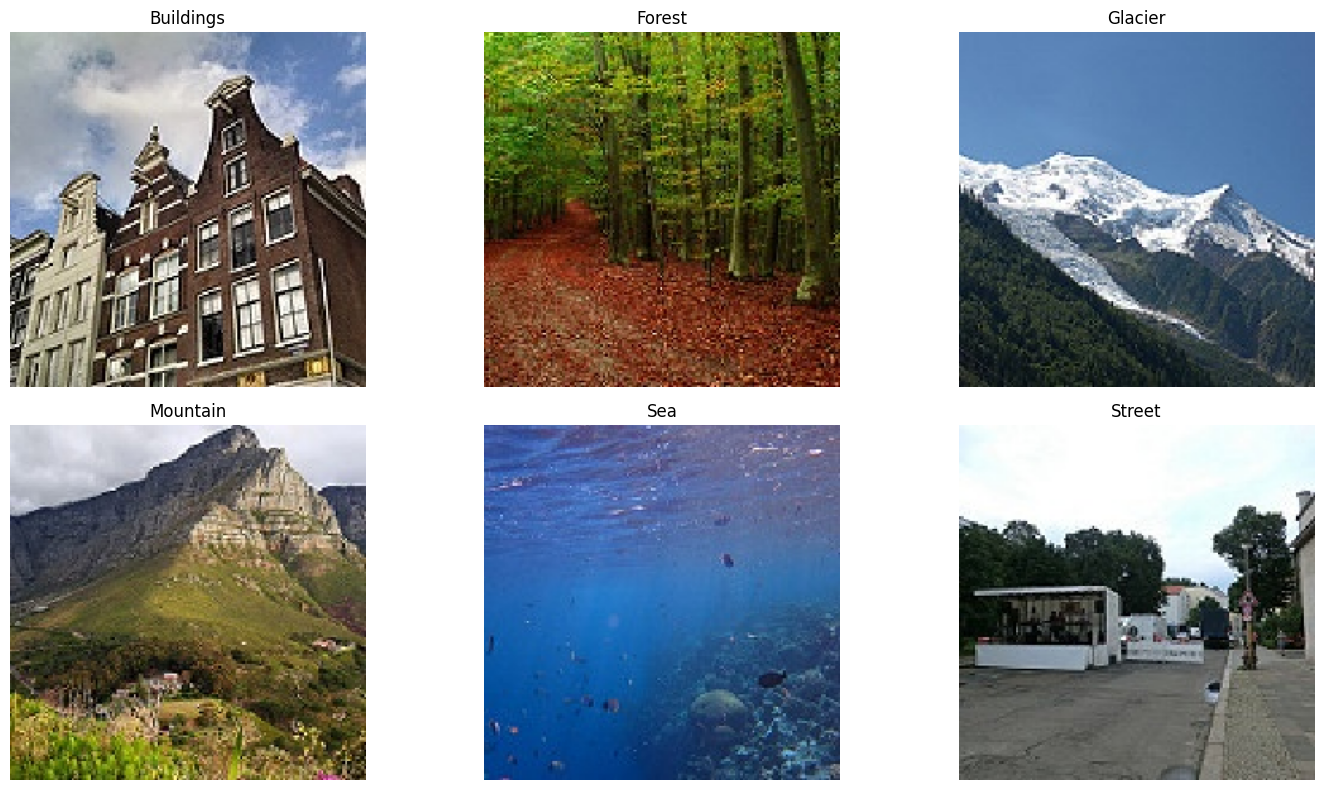

In [ ]:
classes = [
    'buildings',
    'forest',
    'glacier',
    'mountain',
    'sea',
    'street'
]

plt.figure(figsize=(15,8))

for i, classe in enumerate(classes):

    pasta = os.path.join(train_dir, classe)

    arquivo = random.choice(os.listdir(pasta))

    caminho = os.path.join(pasta, arquivo)

    img = image.load_img(caminho, target_size=(224,224))

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(classe.capitalize())
    plt.axis('off')

plt.tight_layout()
plt.show()

### Caracterização da CNN Treinada do Zero

A primeira abordagem consiste na construção de uma Rede Neural Convolucional (CNN) treinada do zero, ou seja, sem a utilização de pesos pré-treinados. Nesse modelo, os parâmetros da rede serão aprendidos exclusivamente a partir das imagens do dataset Intel Image Classification.

A arquitetura foi projetada para realizar a extração hierárquica de características das imagens. As primeiras camadas convolucionais identificam padrões simples, como bordas e texturas, enquanto camadas mais profundas aprendem características mais complexas relacionadas às diferentes categorias presentes no conjunto de dados.

Os principais componentes da arquitetura são:

*   Camadas Convolucionais (Conv2D): responsáveis pela extração automática de características das imagens;
*   Camadas de MaxPooling: utilizadas para reduzir a dimensionalidade dos mapas de características, diminuindo o custo computacional;
*   Camadas Dropout: aplicadas para reduzir o risco de overfitting durante o treinamento;
*   Camadas Densas (Dense): responsáveis pela etapa final de classificação das imagens.

As funções de ativação utilizadas são:

*   ReLU (Rectified Linear Unit): empregada nas camadas intermediárias devido à sua eficiência no treinamento de redes profundas;
*   Softmax: utilizada na camada de saída para gerar as probabilidades associadas às seis classes do problema.

Inicialmente, o modelo será treinado utilizando o otimizador Adam e a função de perda categorical_crossentropy, adequados para problemas de classificação multiclasse.

### CNN Preliminar

A arquitetura inicial foi projetada para aumentar gradualmente a capacidade de extração de características ao longo das camadas da rede. As primeiras camadas convolucionais são responsáveis pela identificação de padrões básicos das imagens, como bordas, cores e texturas. À medida que a profundidade da rede aumenta, passam a ser aprendidas características mais complexas e discriminativas, auxiliando na diferenciação entre as categorias presentes no dataset.

A arquitetura é composta por três blocos convolucionais seguidos de operações de MaxPooling, responsáveis pela redução dimensional dos mapas de características e pela diminuição do custo computacional do treinamento.

Após a etapa de extração de atributos, é aplicada uma camada GlobalAveragePooling2D, responsável por condensar os mapas de características em um vetor de atributos mais compacto. Essa estratégia reduz significativamente a quantidade de parâmetros do modelo quando comparada à utilização da camada Flatten, contribuindo para diminuir o risco de overfitting.

Em seguida, os atributos extraídos são processados por uma camada densa com 128 neurônios e função de ativação ReLU. Para aumentar a capacidade de generalização da rede, foi aplicada uma camada de Dropout com taxa de 50%.

Por fim, a camada de saída utiliza a função de ativação Softmax para estimar as probabilidades associadas a cada uma das seis classes do problema, realizando a classificação final das imagens.

In [ ]:
model = Sequential()

model.add(Input(shape=(224,224,3)))

model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(GlobalAveragePooling2D())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(6, activation='softmax'))

### Resumo da CNN

O resumo da arquitetura permite visualizar a quantidade de camadas, dimensões das saídas e número total de parâmetros treináveis. Essas informações são importantes para avaliar a complexidade do modelo e seu custo computacional durante o treinamento.

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

### Compilação da CNN

Após a definição da arquitetura, o modelo foi compilado utilizando o otimizador Adam e a função de perda categorical_crossentropy.



In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

### Treinamento da CNN

Nesta etapa o modelo é treinado utilizando o conjunto de treinamento e validado a cada época com o conjunto de validação.

In [ ]:
history_cnn = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 213s 582ms/step - accuracy: 0.4218 - loss: 1.3414 - val_accuracy: 0.5474 - val_loss: 1.1232
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 185s 527ms/step - accuracy: 0.5195 - loss: 1.1262 - val_accuracy: 0.5870 - val_loss: 1.0247
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 187s 533ms/step - accuracy: 0.5736 - loss: 1.0486 - val_accuracy: 0.6359 - val_loss: 0.9187
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 186s 530ms/step - accuracy: 0.6124 - loss: 0.9659 - val_accuracy: 0.6601 - val_loss: 0.8779
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 187s 533ms/step - accuracy: 0.6437 - loss: 0.9096 - val_accuracy: 0.6819 - val_loss: 0.8198
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 188s 535ms/step - accuracy: 0.6623 - loss: 0.8654 - val_accuracy: 0.6648 - val_loss: 0.8553
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 192s 547ms/step - accuracy: 0.6794 - loss: 0.8242 - val_accuracy: 0.7079 - val_loss: 0.7843
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 182s 519ms/step - accuracy: 0.6979 -

### Caracterização do Transfer Learning

A segunda abordagem utiliza Transfer Learning com a arquitetura MobileNetV2, pré-treinada no dataset ImageNet.

Essa técnica permite aproveitar características já aprendidas pela rede em um grande conjunto de imagens, reduzindo o tempo de treinamento e melhorando a capacidade de generalização do modelo.

A estratégia adotada consiste em utilizar a MobileNetV2 como extratora de características, mantendo inicialmente seus pesos congelados e adicionando novas camadas densas para realizar a classificação das seis categorias do dataset.

Espera-se que essa abordagem apresente desempenho superior à CNN treinada do zero, tanto em acurácia quanto em eficiência computacional.

### Base Pré-treinada

Antes da construção do modelo completo, é necessário carregar a MobileNetV2 com os pesos aprendidos no ImageNet. Nesta etapa, a camada de classificação original da arquitetura é removida (include_top=False), mantendo apenas o extrator de características.

Além disso, os pesos da rede são inicialmente congelados (trainable=False), permitindo que apenas as novas camadas adicionadas posteriormente sejam treinadas durante os primeiros experimentos.

In [ ]:
IMG_SIZE = (224, 224)

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


### Construção do Modelo com Transfer Learning

Após o carregamento da MobileNetV2 pré-treinada, foram adicionadas novas camadas responsáveis por adaptar a arquitetura ao problema de classificação proposto.

Inicialmente, é aplicada uma camada GlobalAveragePooling2D, que reduz a dimensionalidade dos mapas de características gerados pela rede pré-treinada. Em seguida, é utilizada uma camada densa com função de ativação ReLU para aprendizado das características específicas do dataset, além de uma camada Dropout para auxiliar na redução de overfitting.

Por fim, uma camada de saída com ativação Softmax é utilizada para realizar a classificação das imagens entre as seis categorias presentes no conjunto de dados.

In [ ]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.5)(x)

predictions = Dense(6, activation='softmax')(x)

transfer_model = Model(
    inputs=base_model.input,
    outputs=predictions
)

### Resumo do Modelo

O resumo do modelo permite visualizar a arquitetura final resultante da combinação entre a MobileNetV2 pré-treinada e as novas camadas adicionadas para o problema de classificação. Também são apresentados o número total de parâmetros e a quantidade de parâmetros treináveis.

In [ ]:
transfer_model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Compilação do Modelo

Assim como na CNN treinada do zero, foi utilizado o otimizador Adam e a função de perda categorical_crossentropy, adequados para problemas de classificação multiclasse. A métrica de acurácia será utilizada para avaliar o desempenho do modelo durante o treinamento e validação.

In [ ]:
transfer_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

### Treinamento do Modelo com Transfer Learning

Após a construção do modelo baseado na MobileNetV2, foi realizado o treinamento apenas das camadas adicionadas para classificação, mantendo inicialmente congelados os pesos da rede pré-treinada.

Essa estratégia permite aproveitar o conhecimento previamente adquirido no ImageNet e reduzir significativamente o tempo necessário para treinamento.


In [ ]:
history_transfer = transfer_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 228s 595ms/step - accuracy: 0.8140 - loss: 0.5002 - val_accuracy: 0.8912 - val_loss: 0.2895
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 179s 509ms/step - accuracy: 0.8609 - loss: 0.3752 - val_accuracy: 0.8976 - val_loss: 0.2806
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 184s 524ms/step - accuracy: 0.8763 - loss: 0.3363 - val_accuracy: 0.8948 - val_loss: 0.2804
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 185s 526ms/step - accuracy: 0.8875 - loss: 0.3134 - val_accuracy: 0.8998 - val_loss: 0.2738
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 178s 507ms/step - accuracy: 0.8842 - loss: 0.3117 - val_accuracy: 0.8934 - val_loss: 0.2981
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 184s 525ms/step - accuracy: 0.8871 - loss: 0.3035 - val_accuracy: 0.8998 - val_loss: 0.2817
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 180s 512ms/step - accuracy: 0.8893 - loss: 0.2977 - val_accuracy: 0.8994 - val_loss: 0.2678
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 185s 529ms/step - accuracy: 0.8945 -

### Experimentos Realizados

Nesta etapa foram executados experimentos com duas arquiteturas distintas: uma CNN construída do zero e um modelo baseado em Transfer Learning utilizando a MobileNetV2.

Inicialmente, o planejamento previa a realização de um número maior de combinações de hiperparâmetros, incluindo variações no número de camadas, quantidade de filtros, funções de ativação, tamanho de batch e taxas de dropout. Entretanto, durante a execução dos experimentos foi identificada uma limitação de uso da GPU disponibilizada pelo Google Colab. Após alguns treinamentos completos, o ambiente restringiu temporariamente o acesso à aceleração por hardware, fazendo com que os tempos de execução passassem de poucos minutos para mais de duas horas por experimento.

Dessa forma, foram priorizados experimentos envolvendo a variação do otimizador, permitindo comparar diferentes estratégias de treinamento sem comprometer a viabilidade da execução dentro do prazo disponível.

Os experimentos realizados foram:

| Modelo      | Otimizador |
| ----------- | ---------- |
| CNN         | Adam       |
| CNN         | RMSprop    |
| MobileNetV2 | Adam       |
| MobileNetV2 | RMSprop    |

Os resultados obtidos permitiram avaliar o impacto da escolha do otimizador e comparar o desempenho entre uma rede treinada do zero e uma abordagem baseada em Transfer Learning.


### Métricas de Avaliação
As métricas utilizadas foram:

*   acurácia;
*   loss;
*   tempo de treinamento;
*   gráficos de aprendizado;
*   matriz de confusão.

Também serão analisadas curvas de aprendizado de treino e validação para identificação de overfitting e capacidade de generalização dos modelos.

### Curvas de Aprendizado

As curvas de aprendizado permitem acompanhar a evolução da acurácia e da função de perda ao longo do treinamento.

A comparação entre os conjuntos de treinamento e validação auxilia na identificação de possíveis problemas de overfitting ou underfitting, além de fornecer evidências sobre a capacidade de generalização dos modelos.

### Curvas de Acurácia - CNN

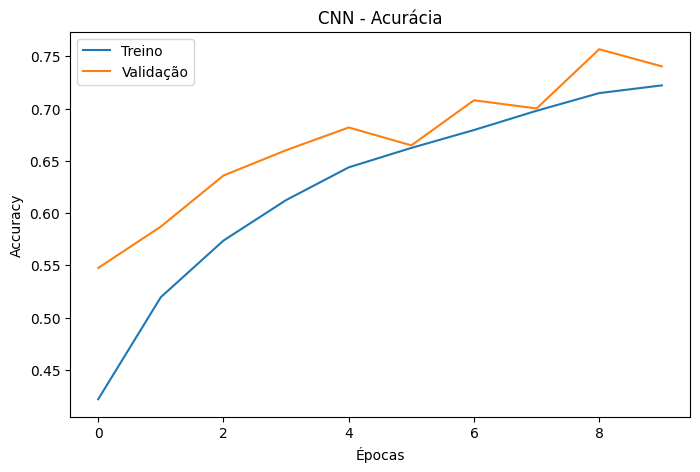

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_cnn.history['accuracy'])
plt.plot(history_cnn.history['val_accuracy'])

plt.title('CNN - Acurácia')
plt.ylabel('Accuracy')
plt.xlabel('Épocas')
plt.legend(['Treino','Validação'])

plt.show()

### Curvas de Loss - CNN

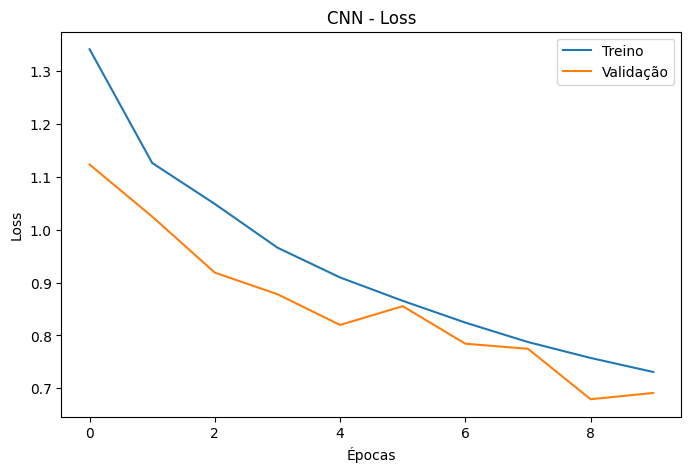

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_cnn.history['loss'])
plt.plot(history_cnn.history['val_loss'])

plt.title('CNN - Loss')
plt.ylabel('Loss')
plt.xlabel('Épocas')
plt.legend(['Treino','Validação'])

plt.show()

### Curvas de Acurácia - MobileNetV2

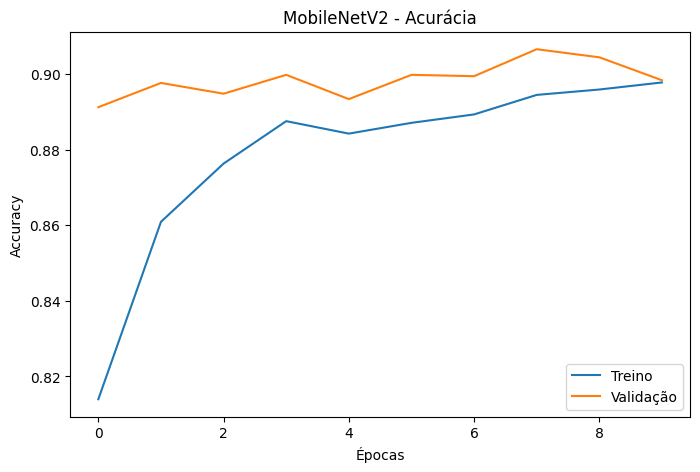

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_transfer.history['accuracy'])
plt.plot(history_transfer.history['val_accuracy'])

plt.title('MobileNetV2 - Acurácia')
plt.ylabel('Accuracy')
plt.xlabel('Épocas')
plt.legend(['Treino','Validação'])

plt.show()

### Curvas de Loss - MobileNetV2

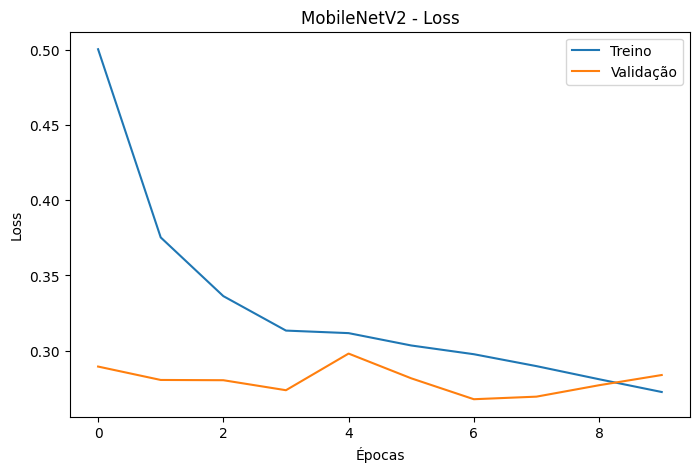

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_transfer.history['loss'])
plt.plot(history_transfer.history['val_loss'])

plt.title('MobileNetV2 - Loss')
plt.ylabel('Loss')
plt.xlabel('Épocas')
plt.legend(['Treino','Validação'])

plt.show()

### Avaliação no Conjunto de Teste

Após o treinamento, os modelos foram avaliados utilizando o conjunto de teste, composto por imagens não utilizadas durante o processo de aprendizado.

Essa avaliação permite medir a capacidade de generalização dos modelos para dados desconhecidos.

### Avaliação da CNN

In [ ]:
cnn_loss, cnn_acc = model.evaluate(test_generator)

print(f"Acurácia CNN: {cnn_acc:.4f}")
print(f"Loss CNN: {cnn_loss:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.7557 - loss: 0.6340
Acurácia CNN: 0.7557
Loss CNN: 0.6340


### Avaliação da MobileNetV2

In [ ]:
transfer_loss, transfer_acc = transfer_model.evaluate(test_generator)

print(f"Acurácia MobileNetV2: {transfer_acc:.4f}")
print(f"Loss MobileNetV2: {transfer_loss:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 174ms/step - accuracy: 0.9007 - loss: 0.2629
Acurácia MobileNetV2: 0.9007
Loss MobileNetV2: 0.2629


###Matriz de Confusão

A matriz de confusão permite analisar detalhadamente o desempenho do modelo em cada uma das classes do problema.

Por meio dessa análise é possível identificar quais categorias apresentam maior facilidade ou dificuldade de classificação.

### Importação

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns

###Matriz de Confusão da MobileNetV2

94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 94ms/step


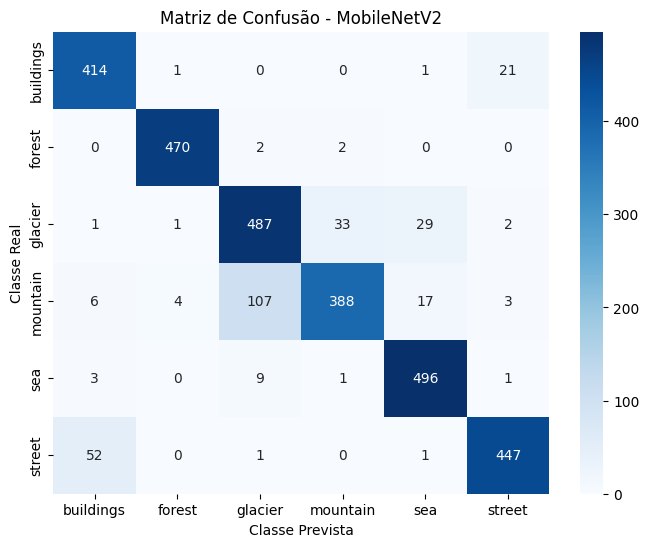

In [ ]:
class_names = [
    'buildings',
    'forest',
    'glacier',
    'mountain',
    'sea',
    'street'
]

predictions = transfer_model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusão - MobileNetV2')
plt.show()

### Análise da Matriz de Confusão

A matriz de confusão permitiu identificar os padrões de acerto e erro do modelo MobileNetV2. As classes Forest e Sea apresentaram os melhores resultados, com taxas de reconhecimento próximas de 99% e 96%, respectivamente.

As maiores dificuldades ocorreram entre as classes Glacier e Mountain, que apresentam características visuais semelhantes relacionadas a relevo, neve e formações rochosas. Também foi observada certa confusão entre as classes Street e Buildings, devido à presença frequente de construções em ambientes urbanos.

Apesar dessas dificuldades, a maioria das classificações concentrou-se na diagonal principal da matriz, indicando elevado desempenho geral do modelo.



###Relatório de Classificação

In [ ]:
print(
    classification_report(
        test_generator.classes,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.87      0.95      0.91       437
      forest       0.99      0.99      0.99       474
     glacier       0.80      0.88      0.84       553
    mountain       0.92      0.74      0.82       525
         sea       0.91      0.97      0.94       510
      street       0.94      0.89      0.92       501

    accuracy                           0.90      3000
   macro avg       0.91      0.90      0.90      3000
weighted avg       0.90      0.90      0.90      3000



###Comparação dos Modelos

Após a realização dos experimentos, os modelos foram comparados considerando a acurácia de validação, o valor da função de perda e a capacidade de generalização.

O modelo baseado em Transfer Learning utilizando a arquitetura MobileNetV2 apresentou desempenho superior ao da CNN treinada do zero em todas as configurações avaliadas. Desde as primeiras épocas observou-se elevada acurácia de validação, resultado do conhecimento previamente adquirido pela rede durante seu treinamento no dataset ImageNet.

Ao final das 10 épocas, a MobileNetV2 treinada com o otimizador Adam atingiu aproximadamente 90,66% de acurácia de validação, enquanto a CNN construída do zero alcançou aproximadamente 77,25%.

A Tabela a seguir resume os principais resultados obtidos.

Comparação dos algoritmos:
| Modelo      | Otimizador | Accuracy Validação |
| ----------- | ---------- | ------------------ |
| CNN         | Adam       | 77,25%             |
| CNN         | RMSprop    | 77,53%             |
| MobileNetV2 | Adam       | 90,66%             |
| MobileNetV2 | RMSprop    | 89,37%             |


Os resultados demonstram que a utilização de Transfer Learning proporciona ganhos significativos de desempenho quando comparada ao treinamento completo de uma rede a partir de pesos aleatórios.


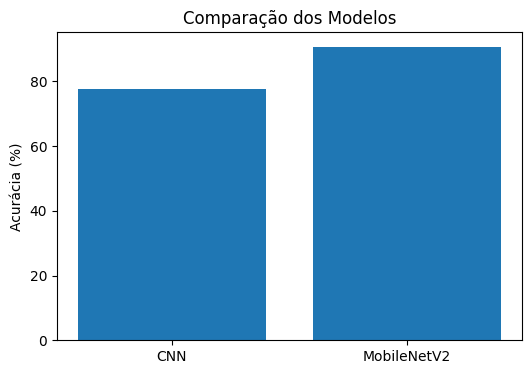

In [ ]:
modelos = ['CNN', 'MobileNetV2']
acuracias = [77.53, 90.66]

plt.figure(figsize=(6,4))
plt.bar(modelos, acuracias)
plt.ylabel('Acurácia (%)')
plt.title('Comparação dos Modelos')
plt.show()

###Discussão dos Resultados

Os resultados obtidos indicam que ambas as arquiteturas foram capazes de aprender características relevantes das imagens presentes no dataset. Entretanto, o modelo baseado em Transfer Learning apresentou desempenho consistentemente superior em todos os experimentos realizados.

A CNN construída do zero atingiu aproximadamente 77% de acurácia de validação, demonstrando boa capacidade de aprendizado mesmo utilizando uma arquitetura relativamente simples. Já a MobileNetV2 alcançou valores próximos de 90% de acurácia, evidenciando a vantagem do aproveitamento de características previamente aprendidas em grandes bases de dados.

A comparação entre os otimizadores Adam e RMSprop mostrou diferenças pouco significativas para este problema específico. Na CNN, o RMSprop apresentou desempenho ligeiramente superior, enquanto na MobileNetV2 o Adam obteve os melhores resultados. Essas diferenças, entretanto, foram pequenas quando comparadas ao impacto causado pela escolha da arquitetura.

Além da maior acurácia, a MobileNetV2 apresentou treinamento mais estável e melhor capacidade de generalização, reforçando a eficácia da técnica de Transfer Learning para problemas de classificação de imagens.

###Conclusão

Neste trabalho foram avaliadas duas abordagens para classificação de imagens utilizando o dataset Intel Image Classification: uma CNN construída manualmente e uma rede baseada em Transfer Learning utilizando a arquitetura MobileNetV2.

A CNN treinada do zero apresentou desempenho satisfatório, alcançando aproximadamente 77% de acurácia no conjunto de validação, demonstrando a capacidade das redes convolucionais em aprender características relevantes diretamente dos dados.

Entretanto, o modelo baseado em Transfer Learning apresentou desempenho significativamente superior, atingindo aproximadamente 91% de acurácia de validação, além de apresentar menor valor de perda e maior estabilidade durante o treinamento.

Os experimentos realizados com os otimizadores Adam e RMSprop mostraram que a escolha do otimizador produziu apenas pequenas variações de desempenho quando comparada ao impacto da arquitetura utilizada. Em ambos os casos, a MobileNetV2 manteve resultados superiores aos obtidos pela CNN construída do zero.

Os resultados obtidos demonstram que a utilização de redes pré-treinadas constitui uma estratégia eficiente para problemas de classificação de imagens, permitindo aproveitar conhecimento previamente adquirido em grandes bases de dados e reduzindo o esforço necessário para treinamento.

Como trabalhos futuros, podem ser avaliadas técnicas de fine tuning da MobileNetV2, arquiteturas mais profundas, diferentes configurações de hiperparâmetros e estratégias adicionais de aumento de dados, buscando melhorias ainda maiores no desempenho dos modelos.

Mesmo utilizando uma arquitetura simples, a CNN construída do zero apresentou desempenho satisfatório. Entretanto, a MobileNetV2 superou significativamente a CNN em todos os cenários avaliados, confirmando a eficácia do Transfer Learning para problemas de classificação de imagens.

### Referências
- KAGGLE. Intel Image Classification Dataset. Disponível em:
https://www.kaggle.com/datasets/puneet6060/intel-image-classification

- TensorFlow Documentation. Disponível em:
https://www.tensorflow.org/

- Keras Documentation. Disponível em:
https://keras.io/

- Don't Use Flatten() - Global Pooling for CNNs with TensorFlow and Keras. Disponível em: https://stackabuse.com/dont-use-flatten-global-pooling-for-cnns-with-tensorflow-and-keras/